# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/Samoa_observations.json`
4. Processed buoy file(s) under `inputs/Observations/processed/` (you build these in the notebook below)

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically.

In [2]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs

## Configuration

Pick buoy sites from the observations GeoJSON (`instrument_id` keys). SnapWave site
labels are `buoy_{instrument_id}`. Point each site to its processed NetCDF (bulk or
spectral) under `inputs/Observations/processed/`.

In [3]:
period = slice("2014-10-23", "2022-06-01")
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99

# instrument_id from inputs/Observations/Samoa_observations.json
buoy_instruments = ["Aunuu_Buoy"]
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]

# Processed observation NetCDF per SnapWave site id
buoy_raw_files = {
    obs.snapwave_site_id("Aunuu_Buoy"): (
        "inputs/Observations/processed/buoy_Anuu_with_spectra.nc"
    ),
}

requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
period         : slice('2014-10-23', '2022-06-01', None)
mda_n          : 450
sites          : ['buoy_Aunuu_Buoy']
requested vars : ['hs', 'tp', 'dir', 'spr']
dynamic path   : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2020.nc
dynamic exists : True


## 1 · Check models

In [4]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Process buoy observations

Load each processed file, rename variables to HyGloW names (`hs`, `tp`, `dir`, `spr`),
slice to `period`, and build a validation dataset on `(time, sites)` with CF-style
attributes. Site metadata (lon/lat/depth) comes from the observations GeoJSON.

In [5]:
# CF-style attributes for validation plots
_BUOY_VAR_ATTRS = {
    "hs": {"standard_name": "sea_surface_wave_significant_height", "units": "m"},
    "tp": {"standard_name": "sea_surface_wave_period", "units": "s"},
    "dir": {"standard_name": "sea_surface_wave_from_direction", "units": "degree"},
    "spr": {
        "standard_name": "sea_surface_wave_directional_spread",
        "units": "degree",
    },
}

chunks: list[xr.Dataset] = []
for site_id in sites:
    raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)

    if "Efth" in raw or "efth" in raw:
        spec_name = "Efth" if "Efth" in raw else "efth"
        stats = raw[spec_name].spec.stats(["hs", "tp", "dm", "dspr"]).load()
        site_ds = stats.rename({"dm": "dir", "dspr": "spr"})
    else:
        rename = {}
        if "dspr" in raw.data_vars and "spr" not in raw.data_vars:
            rename["dspr"] = "spr"
        if rename:
            raw = raw.rename(rename)
        vars_out = {}
        for name in requested_variables:
            if name in raw.data_vars:
                vars_out[name] = raw[name]
            elif name == "dir" and "dm" in raw.data_vars:
                vars_out["dir"] = raw["dm"]
        if "hs" not in vars_out:
            raise ValueError(f"{site_id}: processed buoy file must contain hs or Efth")
        site_ds = xr.Dataset(vars_out)

    site_ds = site_ds.expand_dims(sites=[site_id]).transpose("time", "sites")
    for var, attrs in _BUOY_VAR_ATTRS.items():
        if var in site_ds:
            site_ds[var].attrs.update(attrs)
    chunks.append(obs.attach_buoy_site_meta(site_ds, site_id))

buoy = xr.concat(chunks, dim="sites") if len(chunks) > 1 else chunks[0]
buoy

<xarray.Dataset> Size: 2MB
Dimensions:         (sites: 1, time: 55865)
Coordinates:
  * sites           (sites) object 8B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U4 16B 'buoy'
    site_label      (sites) <U10 40B 'Aunuu_Buoy'
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
    site_depth      (sites) float64 8B -70.0
  * time            (time) datetime64[ns] 447kB 2014-10-23T22:00:00 ... 2022-...
Data variables:
    hs              (time, sites) float64 447kB 1.714 1.632 ... 1.663 1.655
    tp              (time, sites) float32 223kB 11.02 10.38 ... 11.88 11.95
    dir             (time, sites) float64 447kB 130.3 134.4 ... 121.0 122.3
    spr             (time, sites) float64 447kB 49.61 50.91 53.54 ... 59.11 59.3
Attributes:
    standard_name:  sea_surface_wave_significant_height
    units:          m

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in ``Samoa.json`` —
currently WHACS only).

In [ ]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Spectral metamodel": spectral,
    "Dynamic SnapWave": dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for tp is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predicting target variable: hs__PC5
INFO:ExactGPInterpolation:Predicting target variable: hs__PC6
INFO:ExactGPInterpolation:Predicting target variable: hs__PC7
INFO:ExactGPInterpola

## 4 · Metrics vs buoy

In [6]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
    pca_variance=pca_variance,
)

summary = val.metrics_summary(results)
summary

2026-07-14 14:11:10,534 - hyglow.validation - INFO - Computed 4 validation metric row(s)
2026-07-14 14:11:10,543 - hyglow.validation - INFO - Computed 4 validation metric row(s)
2026-07-14 14:11:10,552 - hyglow.validation - INFO - Computed 4 validation metric row(s)
2026-07-14 14:11:10,559 - hyglow.validation - INFO - Computed 4 validation metric row(s)


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.359615,0.420898,0.223383,WHACS (closest goal),Buoy,WHACS (closest goal)
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,3.798607,4.322811,-3.209129,WHACS (closest goal),Buoy,WHACS (closest goal)
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,4.279641,12.467377,0.522553,WHACS (closest goal),Buoy,WHACS (closest goal)
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,spr,Spr,744,1.583932,4.084314,0.398542,WHACS (closest goal),Buoy,WHACS (closest goal)
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.299263,0.414802,0.378663,Bulk metamodel,Buoy,Bulk metamodel
5,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,1.579492,2.148653,-1.118604,Bulk metamodel,Buoy,Bulk metamodel
6,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,3.113515,12.513477,0.519015,Bulk metamodel,Buoy,Bulk metamodel
7,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,spr,Spr,744,-10.344362,11.812600,-12.545582,Bulk metamodel,Buoy,Bulk metamodel
8,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,-0.218785,0.320676,0.592862,Spectral metamodel,Buoy,Spectral metamodel
9,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,0.824819,0.966470,-2.518444,Spectral metamodel,Buoy,Spectral metamodel


## 5 · Scatter plots

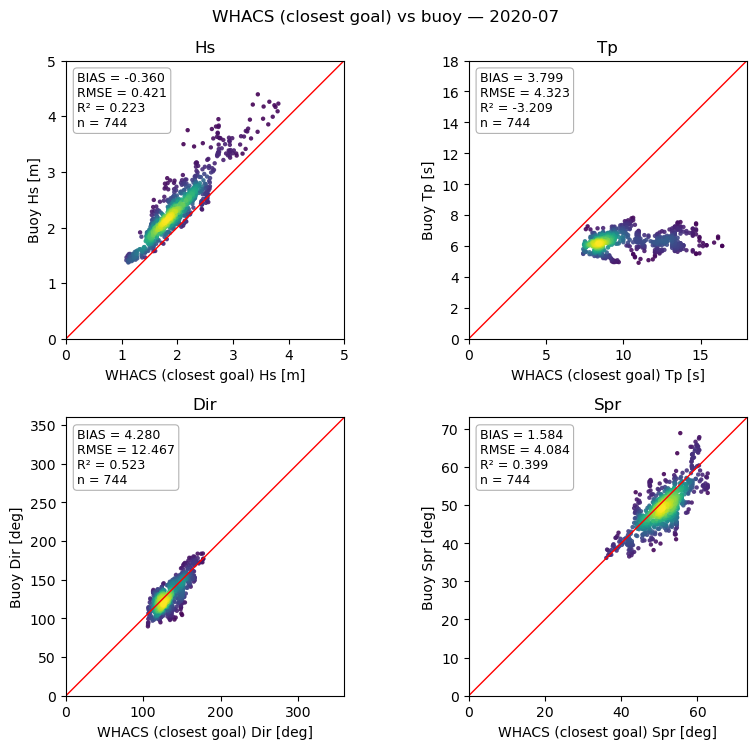

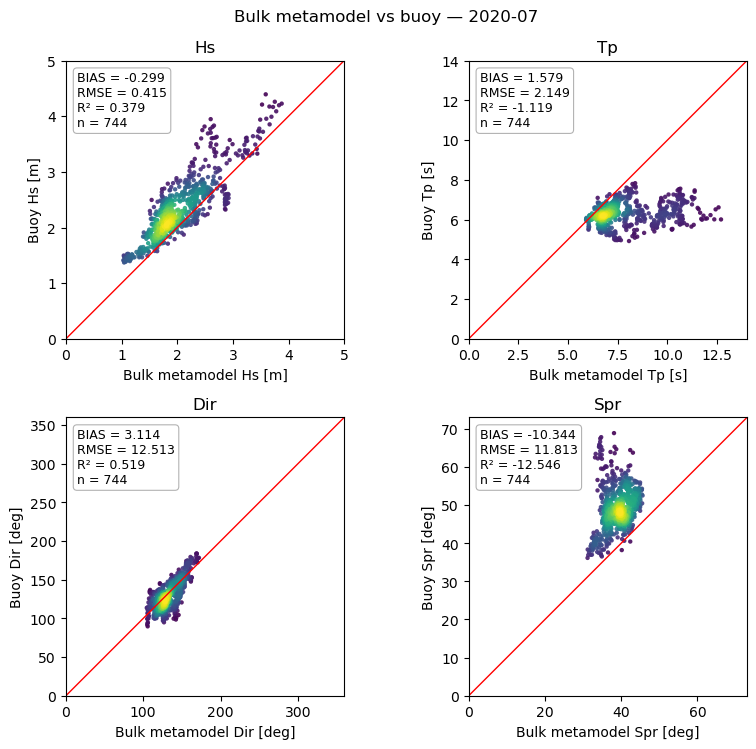

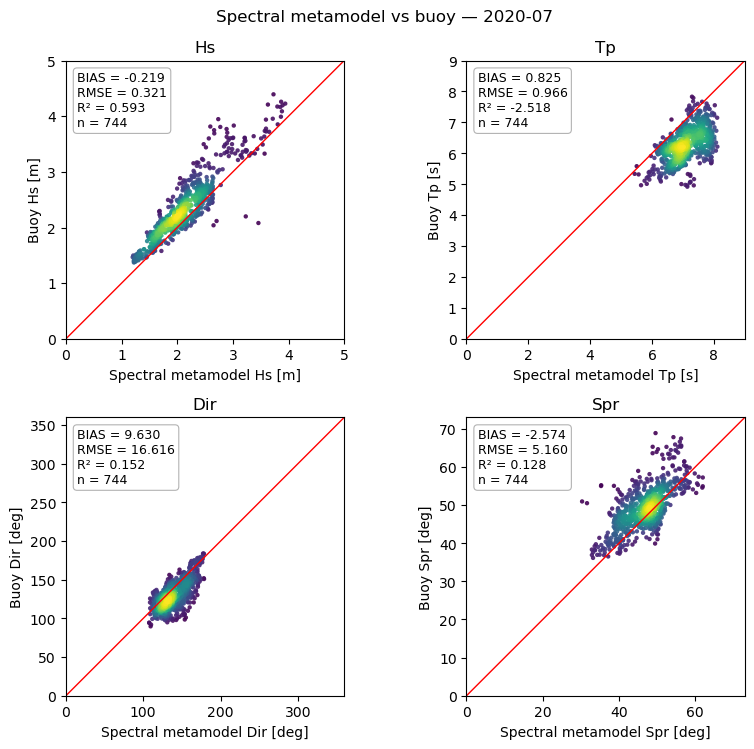

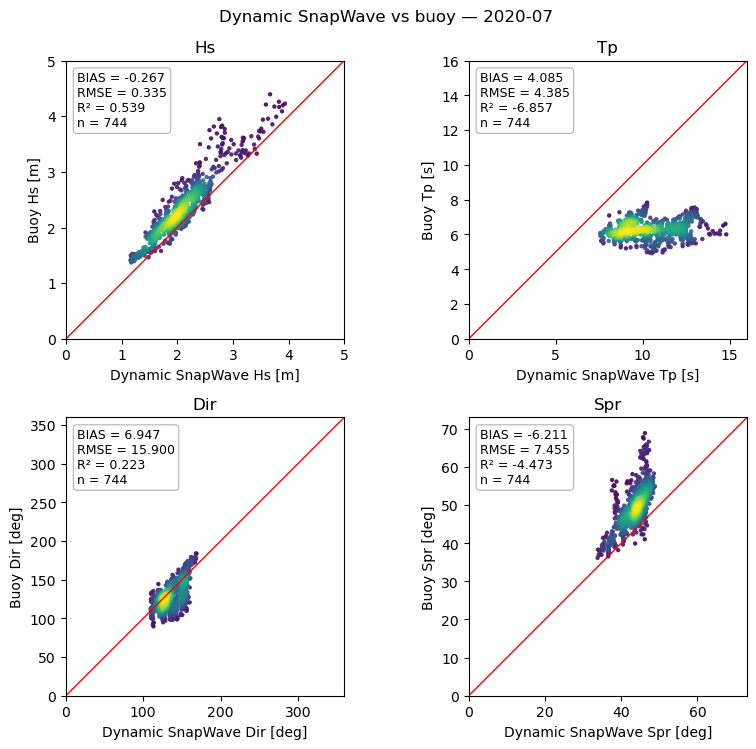

In [7]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

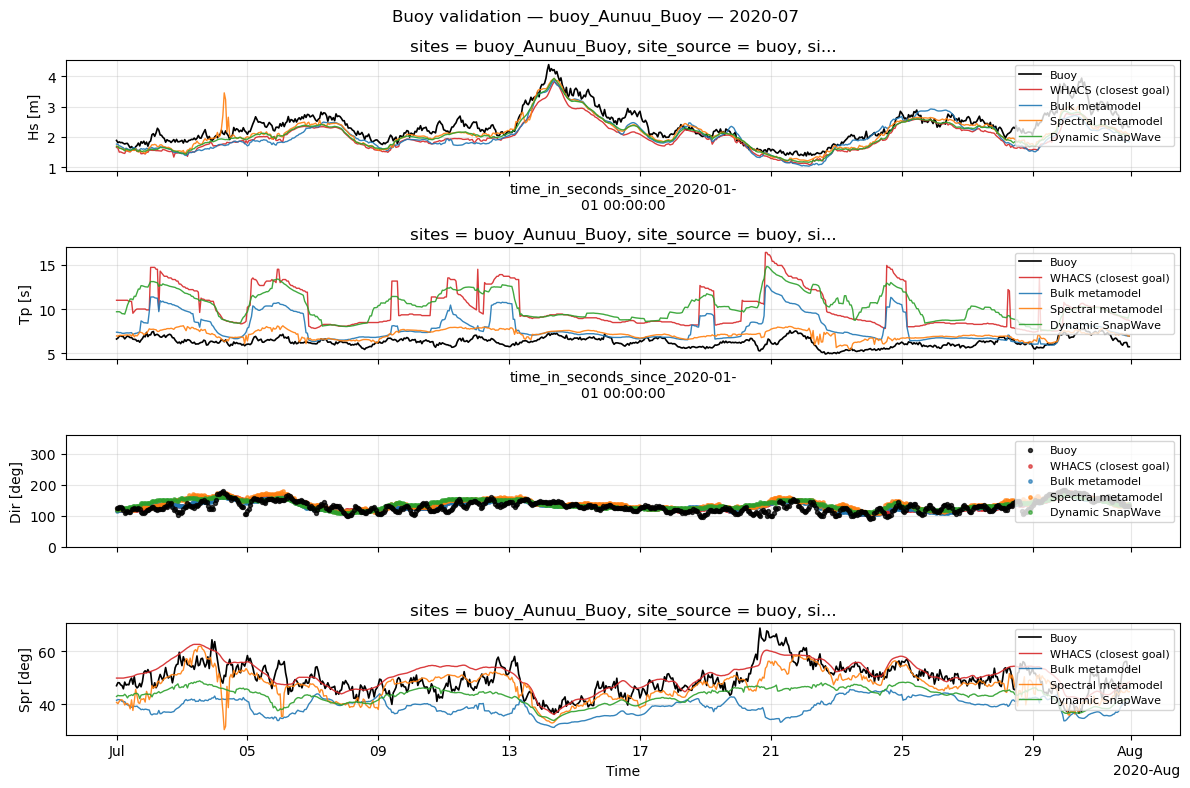

In [8]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()